# Ablation analysis

One notebook, one **section per ablation**, so people can work independently. Each section
*selectively fetches* just its ablation's runs from Google Drive (`ablation_fetch.fetch`), then uses the
**shared helpers** in §0 to load and plot. To work on one ablation, run §0 then jump to that section —
you never download the others.

Data resolution (see `ablation_fetch.py`): a local `experiments-ablations/` checkout if present →
local cache → Drive zip by id (`ablations_manifest.json`). So this runs with no download for whoever has
the raw folders, and downloads a single zip for everyone else.

**Sections:** [A · datasets](#A) · [B · baselines](#B) · [C · gp_kernels](#C) ·
[D · acquisition](#D) · [E-window · window_growth](#Ew) · [E-cost · cost_aware](#Ec)

## 0 · Setup + shared helpers

In [1]:
%matplotlib inline
import sys, glob, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

REPO = Path.cwd().resolve()
while not (REPO / "main.py").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
sys.path.insert(0, str(REPO / "experiments" / "workshop_result" / "analysis"))  # ablation_fetch
from core.utils.data import split_search_space
from scaling.utils import get_pareto_frontier
from core.fitting import build_fit
from core.forms import PARAMETRIC_FORMS
from ablation_fetch import fetch, runs_dir, available, load_manifest

mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "cm", "font.size": 15, "axes.titlesize": 15, "axes.labelsize": 15,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 13,
    "axes.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight", "pdf.fonttype": 42,
})
MANIFEST = load_manifest()
OUT = REPO / "experiments" / "workshop_result" / "analysis" / "out"; OUT.mkdir(parents=True, exist_ok=True)
COEFS = MANIFEST["coefs_default"]                 # ["L0", "A", "alpha"] (all ablations are the L0 form)
FORM_NAME = MANIFEST["form_default"]              # "L0"
PLAB = {"L0":    r"$|\hat{L}_0 - L_0^{\mathrm{val}}|$",
        "A":     r"$|\hat{A} - A^{\mathrm{val}}|$",
        "alpha": r"$|\hat{\alpha} - \alpha^{\mathrm{val}}|$"}
DATA  = REPO / "data"
print("repo:", REPO, "| ablations:", available())

repo: /Users/abhash/Downloads/WORK/surrogate_scaling/surrogate_based_scaling_laws | ablations: ['acquisition', 'baselines', 'cost_aware', 'datasets', 'gp_kernels', 'window_growth']


In [2]:
# --- pre-fetch ALL ablation data up front --------------------------------------------------
# `fetch` resolves each ablation from (1) a sibling `experiments-ablations/<dir>` checkout, else
# (2) `analysis/_ablation_cache/`, else (3) its Drive zip via `drive_id` (needs `gdown`). Looping
# over `available()` downloads *everything we have* once, so every section below finds its runs
# (already-local/cached ablations are returned as-is, only missing ones hit Drive).
for _name in available():
    print(f"{_name:14s} -> {fetch(_name)}")

acquisition    -> /Users/abhash/Downloads/WORK/surrogate_scaling/experiments-ablations/ablation_acquisition
baselines      -> /Users/abhash/Downloads/WORK/surrogate_scaling/experiments-ablations/ablation_baselines
cost_aware     -> /Users/abhash/Downloads/WORK/surrogate_scaling/experiments-ablations/ablation_cost_aware
datasets       -> /Users/abhash/Downloads/WORK/surrogate_scaling/experiments-ablations/ablation_datasets
gp_kernels     -> /Users/abhash/Downloads/WORK/surrogate_scaling/experiments-ablations/ablation_gp_kernels
window_growth  -> /Users/abhash/Downloads/WORK/surrogate_scaling/experiments-ablations/ablation_window_growth


### 0.1 · Load + aggregate

`load_histories(rd, arm)` globs every seed's `history.parquet` for an arm
(`runs/<arm>/<dataset>/<form>/seed_*/<ts>/`). `agg_vs_compute` puts a per-seed per-step (anytime) curve
on a shared log-compute grid and returns median + IQR. These are the two primitives every section uses.

In [3]:
def find_runs(rd, arm, dataset="*", form="*"):
    hits = sorted(glob.glob(str(Path(rd) / arm / dataset / form / "seed_*" / "*" / "history.parquet")))
    return [Path(h).parent for h in hits]

def load_histories(rd, arm, dataset="*", form="*"):
    out = []
    for d in find_runs(rd, arm, dataset, form):
        h = pd.read_parquet(d / "history.parquet"); h.attrs["run_dir"] = str(d); out.append(h)
    return out

def _incumbent(v, signed):
    v = np.asarray(v, float)
    if not signed:
        return np.minimum.accumulate(v)
    out, best = [], v[0]
    for x in v:
        if abs(x) < abs(best): best = x
        out.append(best)
    return np.asarray(out)

def agg_vs_compute(histories, ycol, running=True, signed=False, abs_first=False, npts=80, anchors=None):
    """Median + IQR of a per-step (anytime) curve over seeds (running=False; running=True gives the incumbent). If ``anchors`` (one ``(compute, value)``
    per history, in order) is given, each seed's curve is prepended with that shared init point so all
    arms start from the same place; the grid then spans from the earliest anchor."""
    curves = []
    for i, h in enumerate(histories):
        x = h["total_compute_spent"].to_numpy(float); y = h[ycol].to_numpy(float)
        if abs_first: y = np.abs(y)
        if anchors is not None:
            x0, y0 = anchors[i]; x = np.concatenate([[x0], x]); y = np.concatenate([[y0], y])
        if running: y = _incumbent(y, signed)
        curves.append((x, y))
    if not curves:
        return None
    lo = (min if anchors is not None else max)(x.min() for x, _ in curves)
    hi = min(x.max() for x, _ in curves)
    C = np.geomspace(lo, hi, npts)
    S = np.vstack([np.interp(np.log(C), np.log(x), y) for x, y in curves])
    return C, np.median(S, 0), np.percentile(S, 25, 0), np.percentile(S, 75, 0)

### 0.2 · Envelope set + recovery

For a single-dataset ablation, the **envelope set** is the pool compute-optimal frontier under that
form's split (`oellm_english`, split on `C`, held-out 0.5 by default). **Envelope Set Coverage** = % of
that set on the **obs + fantasized** frontier — the frontier when unacquired pool points are filled with
the surrogate's predictions (`surrogate_predictions.parquet`, `fantasized=True`) — vs cumulative compute.
Used everywhere (the observed-only variant, `fantasized=False`, is available in `agg_recovery` but not
plotted).

In [4]:
_POOL_CACHE = {}
def pool_bundle(csv, split_axis="C", held_out_frac=0.5):
    """Acquirable pool + its compute-optimal envelope set for a dataset/split (cached)."""
    key = (str(csv), split_axis, held_out_frac)
    if key not in _POOL_CACHE:
        d = load_df(csv)
        pool, _ = split_search_space(d.copy(), held_out_frac=held_out_frac, axis=split_axis)
        opt = get_pareto_frontier(pool, x_name="C", y_name="loss")
        _POOL_CACHE[key] = dict(pool_df=pool, PSET=set(int(i) for i in opt.index))
    return _POOL_CACHE[key]

def envelope_set(csv, split_axis="C", held_out_frac=0.5):
    return pool_bundle(csv, split_axis, held_out_frac)["PSET"]

def envelope_curve(h, pset):                                     # observed: which frontier pts were acquired
    C = h["total_compute_spent"].to_numpy(float)
    frac = [len(pset & set(int(x) for x in row["acquired_idx"])) / len(pset) for _, row in h.iterrows()]
    return C, np.asarray(frac) * 100.0

def _frontier_idx(C, loss, idx):
    order = np.lexsort((loss, C)); Cs, ls, ids = C[order], loss[order], idx[order]
    uniq = np.concatenate([[True], Cs[1:] != Cs[:-1]]); ls, ids = ls[uniq], ids[uniq]
    keep, m = np.zeros(len(ls), bool), np.inf
    for i, l in enumerate(ls):
        if l < m: keep[i] = True; m = l
    return set(int(i) for i in ids[keep])

def fantasized_curve(h, pool):                                  # obs + fantasized: frontier under surrogate fill
    spp = Path(h.attrs["run_dir"]) / "surrogate_predictions.parquet"
    if not spp.exists():                                        # model-free arm (e.g. RS): no surrogate to fantasize
        return envelope_curve(h, pool["PSET"])
    sp = pd.read_parquet(spp)
    pdf = pool["pool_df"]; C_pool = pdf["C"].to_numpy(float); idx_pool = pdf.index.to_numpy()
    true_loss = pdf["loss"].to_numpy(float); pos = {int(i): k for k, i in enumerate(idx_pool)}; pset = pool["PSET"]
    comp = h.set_index("iter")["total_compute_spent"]; xs, ys = [], []
    for it, g in sp.groupby("iter"):
        loss = true_loss.copy()
        m = [int(i) in pos for i in g["idx"]]; gi = g[m]         # keep only surrogate preds over the pool
        p = np.array([pos[int(i)] for i in gi["idx"]], dtype=int)
        if len(p): loss[p] = gi["pred_loss"].to_numpy(float)
        fidx = _frontier_idx(C_pool, loss, idx_pool)
        xs.append(float(comp.loc[it])); ys.append(len(fidx & pset) / len(pset) * 100)
    return np.asarray(xs), np.asarray(ys)

def agg_curves(curves, anchors=None, npts=80):
    if anchors is not None:
        curves = [(np.concatenate([[a[0]], x]), np.concatenate([[a[1]], y])) for a, (x, y) in zip(anchors, curves)]
    curves = [c for c in curves if len(c[0]) > 1]
    if not curves:
        return None
    lo = (min if anchors is not None else max)(x.min() for x, _ in curves); hi = min(x.max() for x, _ in curves)
    g = np.geomspace(lo, hi, npts)
    S = np.vstack([np.interp(np.log(g), np.log(x), y) for x, y in curves])
    return g, np.median(S, 0), np.percentile(S, 25, 0), np.percentile(S, 75, 0)

def agg_recovery(histories, pool, anchors=None, fantasized=False):
    fn = (lambda h: fantasized_curve(h, pool)) if fantasized else (lambda h: envelope_curve(h, pool["PSET"]))
    return agg_curves([fn(h) for h in histories], anchors=anchors)

### 0.25 · Shared init anchor

All arms in an ablation share the **same init points** for a given seed (verified). To make the plots
start from that common point, `init_fits` fits the `L0` form on each seed's 10-point init set (from the
history's own iter-0, before the loop) and returns `(init_compute, interpretable_params, init_index_set)`
per seed. Regret and envelope curves are then prepended with this shared anchor via `anchors=`.

In [5]:
FORM = PARAMETRIC_FORMS[FORM_NAME]

def val_ref(rd, arm, dataset="*", form="*"):
    """Acquirable-pool reference fit (interpretable coefs) — arm/seed-invariant per dataset."""
    d = find_runs(rd, arm, dataset, form)[0]
    return json.loads((d / "ref_fits.json").read_text())["validation"]["interpretable"]

def init_fits(histories, df):
    """Per-seed shared init: (compute, {coef: value}, init_idx_set) from fitting the 10 init points."""
    out = []
    for h in histories:
        r0 = h.iloc[0]
        idx = set(int(i) for i in r0["acquired_idx"]); idx.discard(int(r0["new_idx"]))
        idf = df.loc[df.index.intersection(sorted(idx))]
        p, _ = build_fit(idf, form_name=FORM_NAME, y_name="loss", fit_quality="dense")
        out.append((float(idf["C"].sum()), FORM.interpretable(np.asarray(p, float)), set(idx)))
    return out

def load_df(csv):
    d = pd.read_csv(csv); d["C"] = 6.0 * d["N"] * d["D"]; return d

def ensure_csv(csv, source):
    """Ensure the preprocessed CSV for `source` exists with a clean N/D/loss schema, fetching the raw
    data and applying the source adapter on demand. Works around preprocess.py's main() not applying
    adapters, and covers `oellm_english` (needed by every single-dataset section) which is gitignored
    and not shipped. No-op when the CSV is already present + clean. Returns Path or None."""
    if csv is None:
        return None
    csv = Path(csv)
    if csv.exists() and {"N", "D", "loss"}.issubset(pd.read_csv(csv, nrows=1).columns):
        return csv
    try:
        import importlib
        sys.path.insert(0, str(REPO / "preprocessing"))
        FD = importlib.import_module("fetch_data"); PP = importlib.import_module("preprocess")
        print(f"  [{source}] preprocessed CSV missing -> fetching raw + building ...")
        if source.startswith("porian"):
            c = FD.URL_SOURCES["porian"]; FD.fetch_url("porian", c["url"], c["filename"])
            df = PP.READERS["pickle"](REPO / "data" / "porian" / "raw" / c["filename"])
        elif source == "oellm_english":
            c = FD.GIT_SOURCES["oellm_english"]; FD.fetch_git("oellm_english", c["repo"], c["paths"])
            df = PP.READERS["csv"](REPO / "data" / "oellm_english" / "raw" / "all_points_clean.csv")
        elif source == "oellm_multilingual":
            c = FD.GIT_SOURCES["oellm_multilingual"]; FD.fetch_git("oellm_multilingual", c["repo"], c["paths"])
            df = PP.READERS["csv"](REPO / "data" / "oellm_multilingual" / "raw" / "decay_points_clean.csv")
        elif source in ("steplaw_dense", "steplaw_moe"):
            c = FD.GIT_SOURCES["steplaw"]; FD.fetch_git("steplaw", c["repo"], c["paths"])
            fn = "dense_lr_bs_loss.csv" if source == "steplaw_dense" else "moe_lr_bs_loss.csv"
            df = PP.READERS["csv"](REPO / "data" / "steplaw" / "raw" / fn)
        elif source == "warmstart":                        # raw is a Drive download; adapter is None
            c = FD.URL_SOURCES["warmstart"]; FD.fetch_url("warmstart", c["url"], c["filename"])
            df = PP.READERS["csv"](REPO / "data" / "warmstart" / "raw" / c["filename"])
        else:
            return csv if csv.exists() else None
        adapt = PP.ADAPTERS[source][0]
        if adapt is not None:
            df = adapt(df)
        if {"N", "D", "loss"}.issubset(df.columns):
            df = df[[c for c in PP.COLUMNS if c in df.columns]].reset_index(drop=True)
        csv.parent.mkdir(parents=True, exist_ok=True); df.to_csv(csv, index=False)
        return csv
    except Exception as e:
        print(f"  [{source}] auto-build failed ({type(e).__name__}: {e})")
        return None

### 0.3 · One-call recovery strip

`recovery_strip(name, arms, csv, ...)` draws the standard strip for a single-dataset ablation:
`COEFS` regret panels `|θ̂ − θ_val|` + one envelope-recovery panel, every arm overlaid (median + IQR),
saved to `out/fig_abl_<name>.pdf`. Sections call it in one line, then customise as needed.

In [6]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00", "#000000"]

def arm_colors(arms):
    return {a: PALETTE[i % len(PALETTE)] for i, a in enumerate(arms)}

def recovery_strip(name, arms, csv, split_axis="C", held_out_frac=0.5, title=None, save=True):
    rd = runs_dir(name)
    hist = {a: load_histories(rd, a) for a in arms}
    hist = {a: h for a, h in hist.items() if h}          # keep arms that actually have runs
    if not hist:
        print(f"[{name}] no runs found under {rd}"); return
    csv = ensure_csv(csv, "oellm_english")               # build the (gitignored) oellm_english CSV on demand
    if csv is None:
        print(f"[{name}] oellm_english CSV unavailable; skipping"); return
    cols = arm_colors(arms); pool = pool_bundle(csv, split_axis, held_out_frac); pset = pool["PSET"]
    df = load_df(csv); vref = val_ref(rd, next(iter(hist)))
    fits = {a: init_fits(hs, df) for a, hs in hist.items()}   # shared init anchor per seed (same points)
    ncol = len(COEFS) + 1
    fig, ax = plt.subplots(1, ncol, figsize=(3.3 * ncol, 3.1))
    for j, coef in enumerate(COEFS):
        for a, hs in hist.items():
            anc = [(c, abs(interp[coef] - vref[coef])) for c, interp, _ in fits[a]]
            r = agg_vs_compute(hs, f"regret_val_{coef}", signed=True, abs_first=True, anchors=anc, running=False)
            if r is None: continue
            Cg, med, lo, hi = r
            ax[j].plot(Cg, med, color=cols[a], lw=1.5, label=arms[a]); ax[j].fill_between(Cg, lo, hi, color=cols[a], alpha=0.15, lw=0)
        ax[j].set_xscale("log"); ax[j].set_yscale("log")
        ax[j].set_title(PLAB[coef])
        ax[j].set_xlabel("cumulative compute (FLOPs)")
    for a, hs in hist.items():                            # coverage: obs + fantasized frontier
        anc = [(c, len(pset & iset) / len(pset) * 100) for c, _, iset in fits[a]]
        r = agg_recovery(hs, pool, anchors=anc, fantasized=True)
        if r is None: continue
        g, med, lo, hi = r
        ax[-1].plot(g, med, color=cols[a], lw=1.7, label=arms[a]); ax[-1].fill_between(g, lo, hi, color=cols[a], alpha=0.15, lw=0)
    ax[-1].set_xscale("log"); ax[-1].set_ylim(0, 101); ax[-1].set_title("Envelope Set Coverage (obs + fantasized)"); ax[-1].set_xlabel("cumulative compute (FLOPs)")
    for a in ax: a.grid(which="major", ls=":", lw=0.4, alpha=0.4)
    handles = [Line2D([], [], color=cols[a], lw=1.8, label=lbl) for a, lbl in arms.items() if a in hist]
    fig.legend(handles, [h.get_label() for h in handles], loc="lower center", ncol=min(len(handles), 6),
               frameon=True, bbox_to_anchor=(0.5, -0.10))
    fig.suptitle(title or name, y=1.02, fontsize=16)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    if save: fig.savefig(OUT / f"fig_abl_{name}.pdf")
    plt.show()
    print(f"[{name}] arms with runs: {list(hist)} | {len(pset)} envelope pts")

<a id="A"></a>
## A · datasets

Window generalization across datasets (`ablation_datasets`). Multi-dataset, so it is handled per dataset rather than by `recovery_strip`: coefficient regret + obs+fantasized coverage per dataset, arms separated by linestyle, anchored at the shared init. `ensure_dataset_csv` fetches + builds each dataset's CSV on demand (applying the porian adapter that `preprocess.py` skips), so no data needs to be committed; porian aside, the raw files already carry `N/D/loss`.

datasets present: ['oellm_multilingual', 'porian_main_stable_rw', 'steplaw_dense', 'warmstart_surrogate']


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


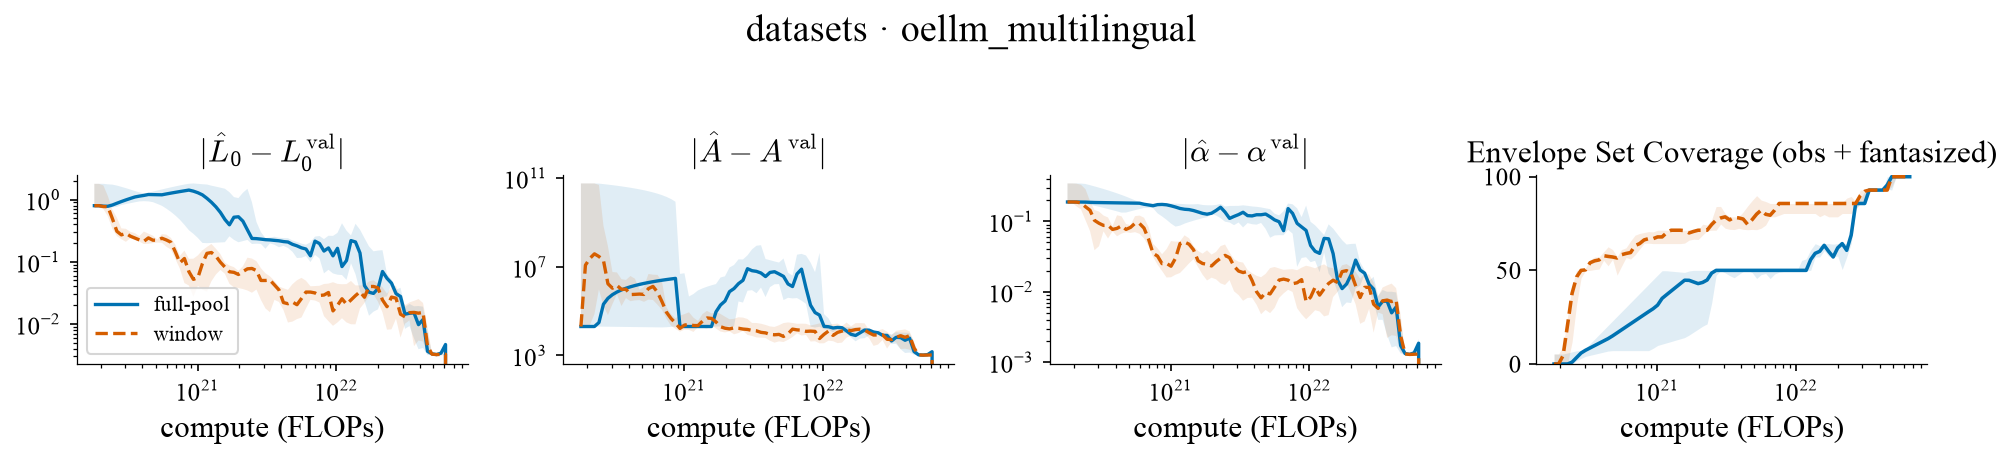

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


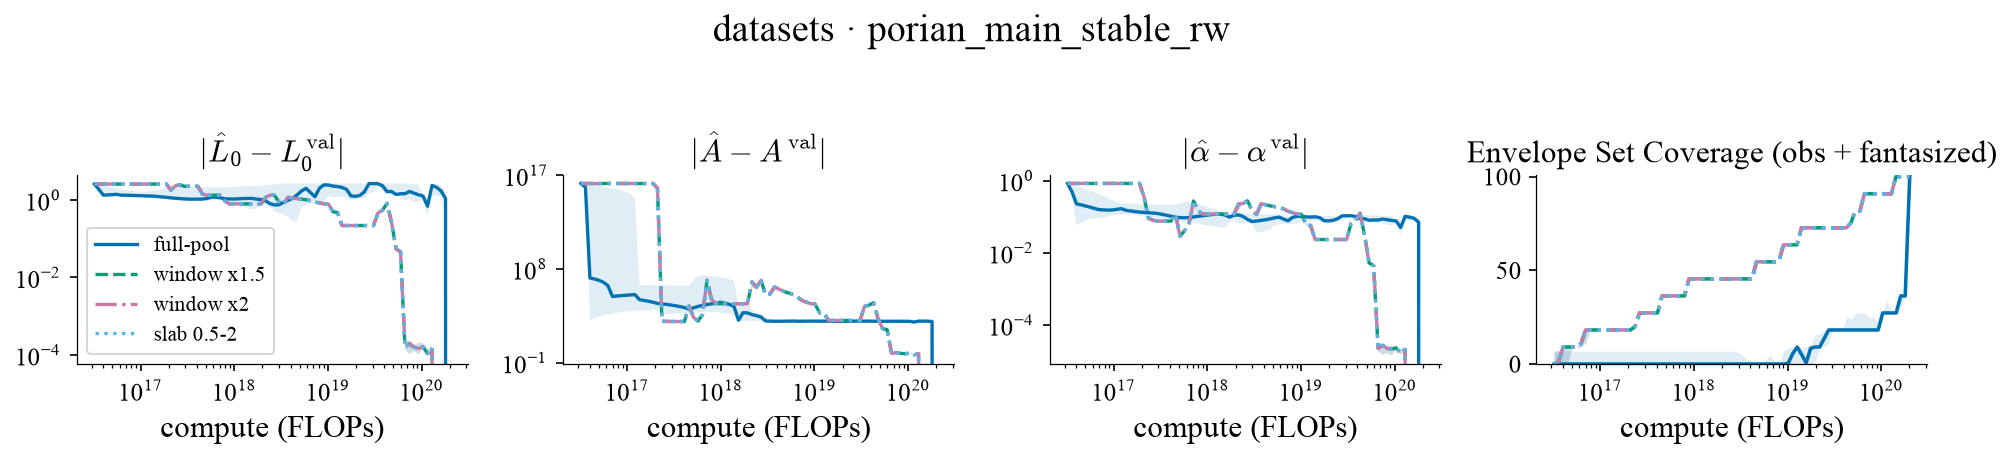

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


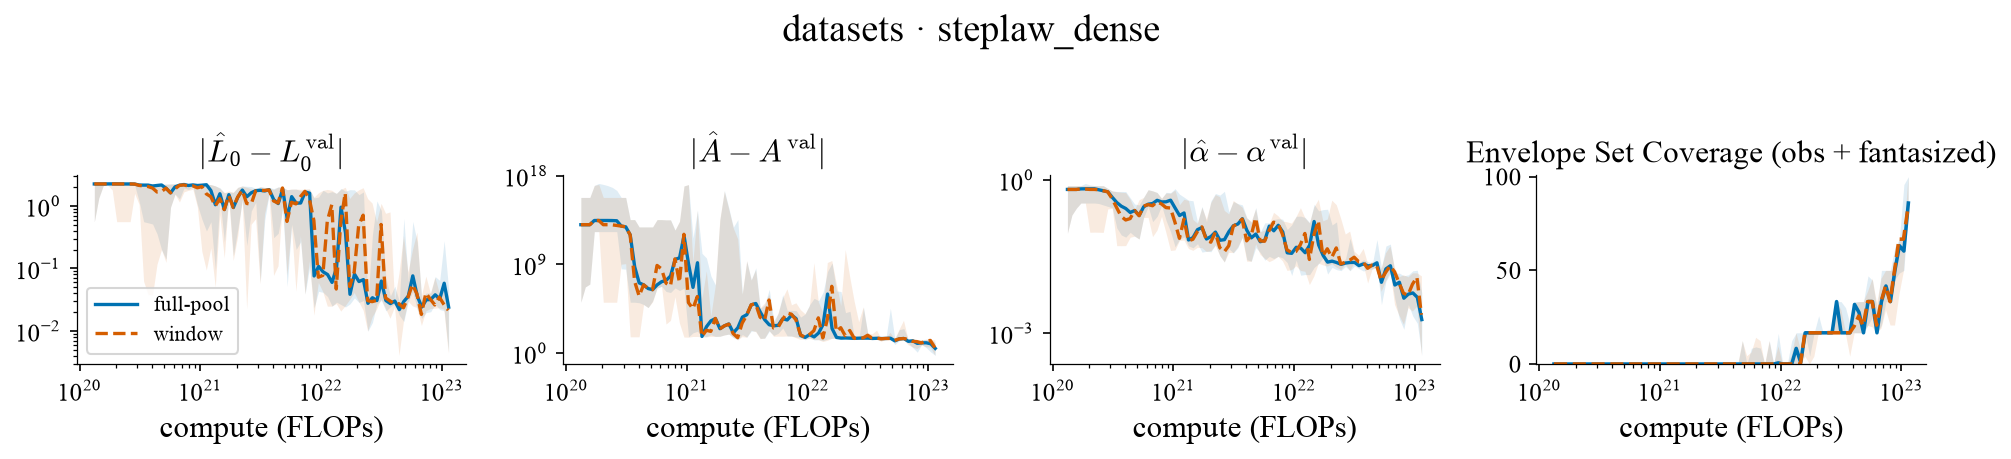

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


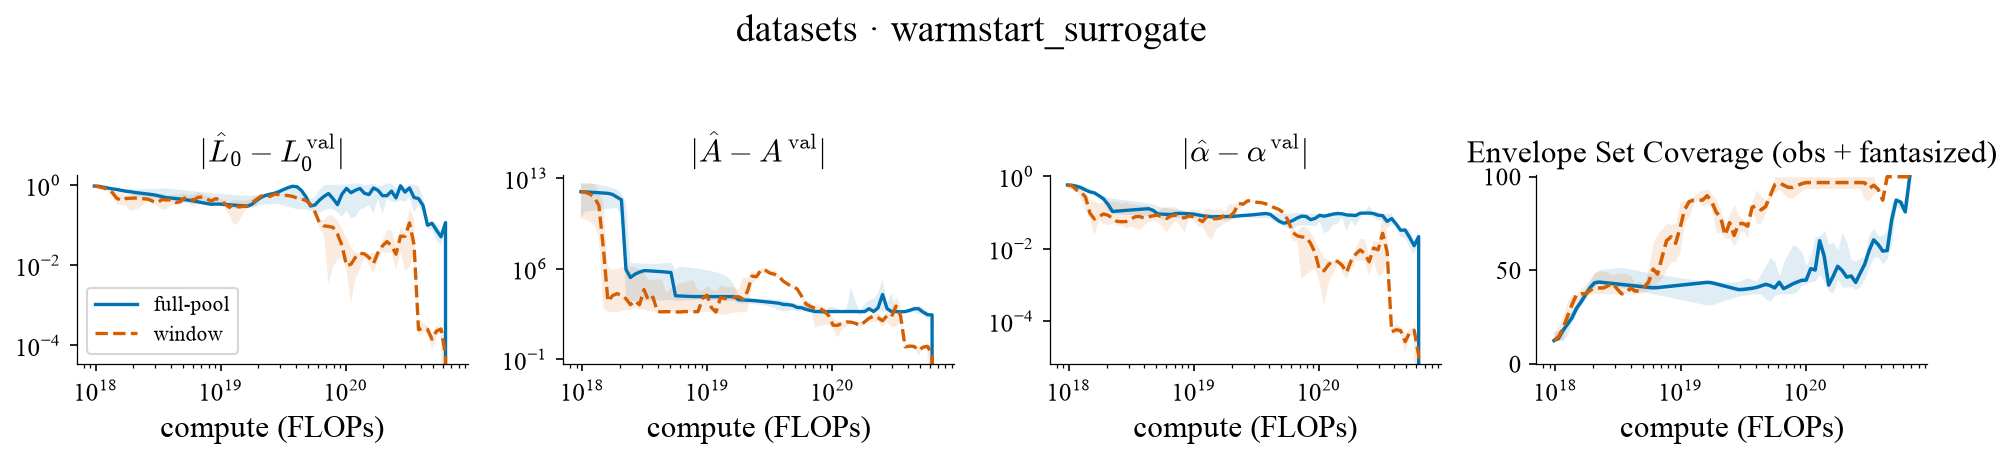

In [7]:
arms = MANIFEST["ablations"]["datasets"]["arms"]
abl = fetch("datasets")                                # ablation_datasets folder (incl. nested warmstart/)
LS = ["-", "--", "-.", ":"]
# discover ALL runs recursively so the nested warmstart sub-experiment is included too:
#   <base>/runs/<arm>/<dataset>/<form>/seed_*/<ts>/   (base = abl for the main datasets, abl/warmstart for warmstart)
runs_by = {}                                           # (dataset, arm) -> [run dirs]
for h in glob.glob(str(abl / "**" / "seed_*" / "*" / "history.parquet"), recursive=True):
    p = Path(h).parent
    runs_by.setdefault((p.parents[2].name, p.parents[3].name), []).append(p)
datasets = sorted({d for d, _ in runs_by})
print("datasets present:", datasets)
cols = arm_colors(list(arms))

def resolve_csv(run_dir, ds):
    """Locate a dataset's input CSV. data/<...> is built on demand (ensure_csv); a CSV bundled next to
    the runs -- e.g. warmstart's warmstart_surrogate.csv -- is found by walking up from the run dir."""
    inp = json.loads((run_dir / "args.json").read_text())["args"].get("input")
    if not inp:
        return None
    if inp.startswith("data/"):
        return ensure_csv(REPO / inp, ds)
    if (REPO / inp).exists():
        return REPO / inp
    base = Path(inp).name                              # bundled CSV: search upward from the run dir
    for par in run_dir.parents:
        if (par / base).exists():
            return par / base
    return None

def hists(dirs):                                       # load histories (with run_dir attr) from explicit dirs
    out = []
    for d in dirs:
        hh = pd.read_parquet(d / "history.parquet"); hh.attrs["run_dir"] = str(d); out.append(hh)
    return out

for ds in datasets:
    present = sorted({a for (dd, a) in runs_by if dd == ds},
                     key=lambda a: list(arms).index(a) if a in arms else 99)
    lsty = {a: LS[i % len(LS)] for i, a in enumerate(present)}
    r0 = runs_by[(ds, present[0])][0]
    csv = resolve_csv(r0, ds)
    df, reason = None, "no CSV"
    if csv is not None:
        d0 = pd.read_csv(csv)
        if {"N", "D", "loss"}.issubset(d0.columns):
            d0 = d0.copy(); d0["C"] = 6.0 * d0["N"] * d0["D"]
            acq = set(int(i) for i in pd.read_parquet(r0 / "history.parquet").iloc[0]["acquired_idx"])
            df, reason = (d0, "ok") if acq.issubset(set(d0.index)) else (None, "index misalignment")
        else:
            reason = "non-standard schema"
    have = df is not None
    if have:
        pooltmp, _ = split_search_space(df.copy(), held_out_frac=0.5, axis="C")
        opt = get_pareto_frontier(pooltmp, x_name="C", y_name="loss")
        pool = dict(pool_df=pooltmp, PSET=set(int(i) for i in opt.index)); pset = pool["PSET"]
        vref = json.loads((r0 / "ref_fits.json").read_text())["validation"]["interpretable"]
        fits = {a: init_fits(hists(runs_by[(ds, a)]), df) for a in present}
    ncol = len(COEFS) + (1 if have else 0)
    fig, ax = plt.subplots(1, ncol, figsize=(3.3 * ncol, 3.0), squeeze=False); ax = ax[0]
    for j, coef in enumerate(COEFS):
        for a in present:
            H = hists(runs_by[(ds, a)])
            anc = [(c, abs(interp[coef] - vref[coef])) for c, interp, _ in fits[a]] if have else None
            r = agg_vs_compute(H, f"regret_val_{coef}", signed=True, abs_first=True, anchors=anc, running=False)
            if r is None: continue
            Cg, med, lo, hi = r
            ax[j].plot(Cg, med, color=cols[a], lw=1.6, ls=lsty[a], label=arms.get(a, a)); ax[j].fill_between(Cg, lo, hi, color=cols[a], alpha=0.12, lw=0)
        ax[j].set_xscale("log"); ax[j].set_yscale("log"); ax[j].set_title(PLAB[coef]); ax[j].set_xlabel("compute (FLOPs)")
    if have:                                            # obs+fantasized coverage (arms kept distinct by linestyle)
        for a in present:
            H = hists(runs_by[(ds, a)])
            anc = [(c, len(pset & iset) / len(pset) * 100) for c, _, iset in fits[a]]
            r = agg_recovery(H, pool, anchors=anc, fantasized=True)
            if r is None: continue
            g, med, lo, hi = r
            ax[-1].plot(g, med, color=cols[a], lw=1.7, ls=lsty[a], label=arms.get(a, a)); ax[-1].fill_between(g, lo, hi, color=cols[a], alpha=0.12, lw=0)
        ax[-1].set_xscale("log"); ax[-1].set_ylim(0, 101); ax[-1].set_title("Envelope Set Coverage (obs + fantasized)"); ax[-1].set_xlabel("compute (FLOPs)")
    ax[0].legend(fontsize=10)
    fig.suptitle(f"datasets · {ds}" + ("" if have else f"  ({reason} -> no shared-init anchor / coverage)"), y=1.03)
    fig.tight_layout(); fig.savefig(OUT / f"fig_abl_datasets_{ds}.pdf"); plt.show()

<a id="B"></a>
## B · baselines

Method families (`ablation_baselines`): RS vs GP+EI (ours) vs TabPFN-BO vs XGBoost-ens on `oellm_english`. One-call strip.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


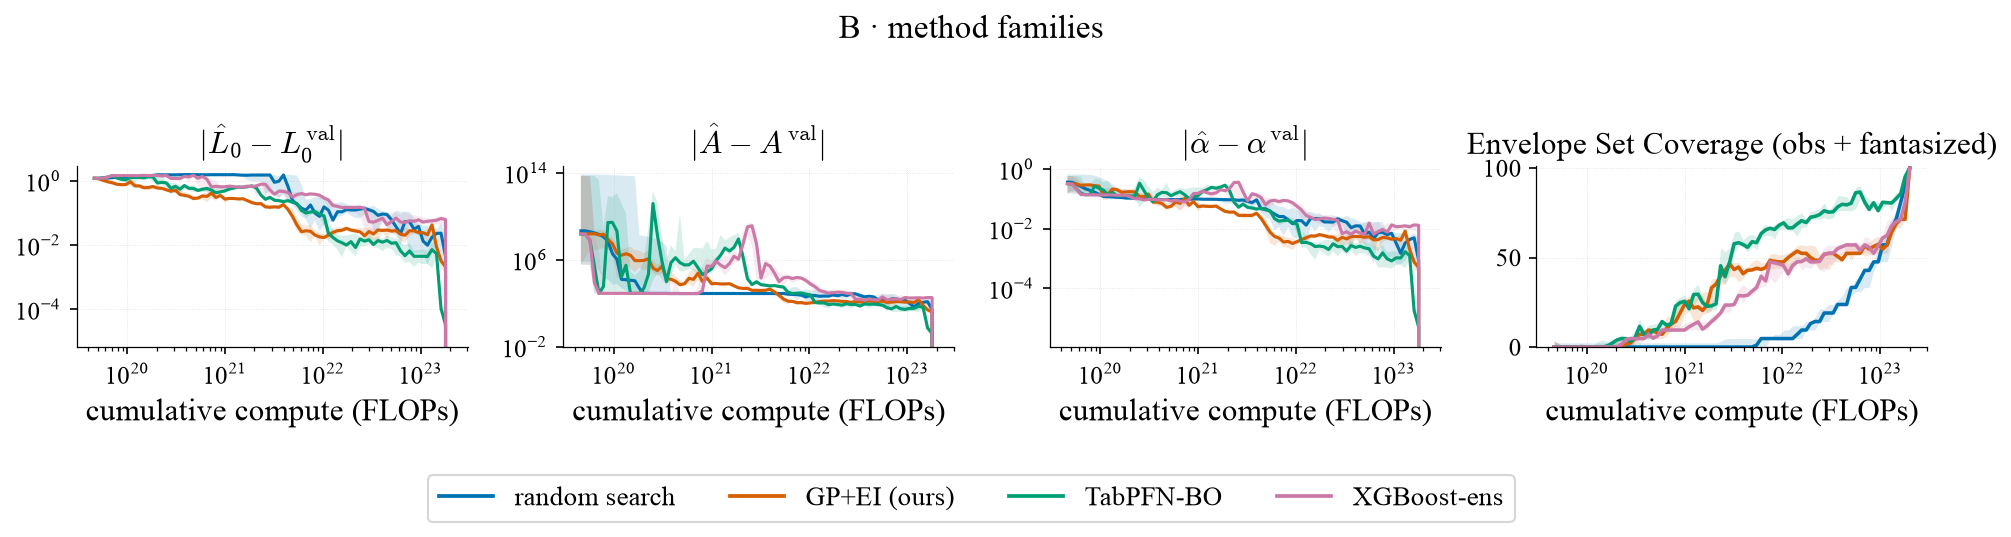

[baselines] arms with runs: ['rs', 'bo_ei', 'tabpfn_bo', 'xgb_ens'] | 21 envelope pts


In [8]:
arms = MANIFEST["ablations"]["baselines"]["arms"]
recovery_strip("baselines", arms, DATA / "oellm_english" / "preprocessed" / "oellm_english.csv",
               title="B · method families")

<a id="C"></a>
## C · gp_kernels

GP kernel choice (`ablation_gp_kernels`): matern / linear / linear+matern / linear_nd+matern_hp, plus a full-pool `vanilla`.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


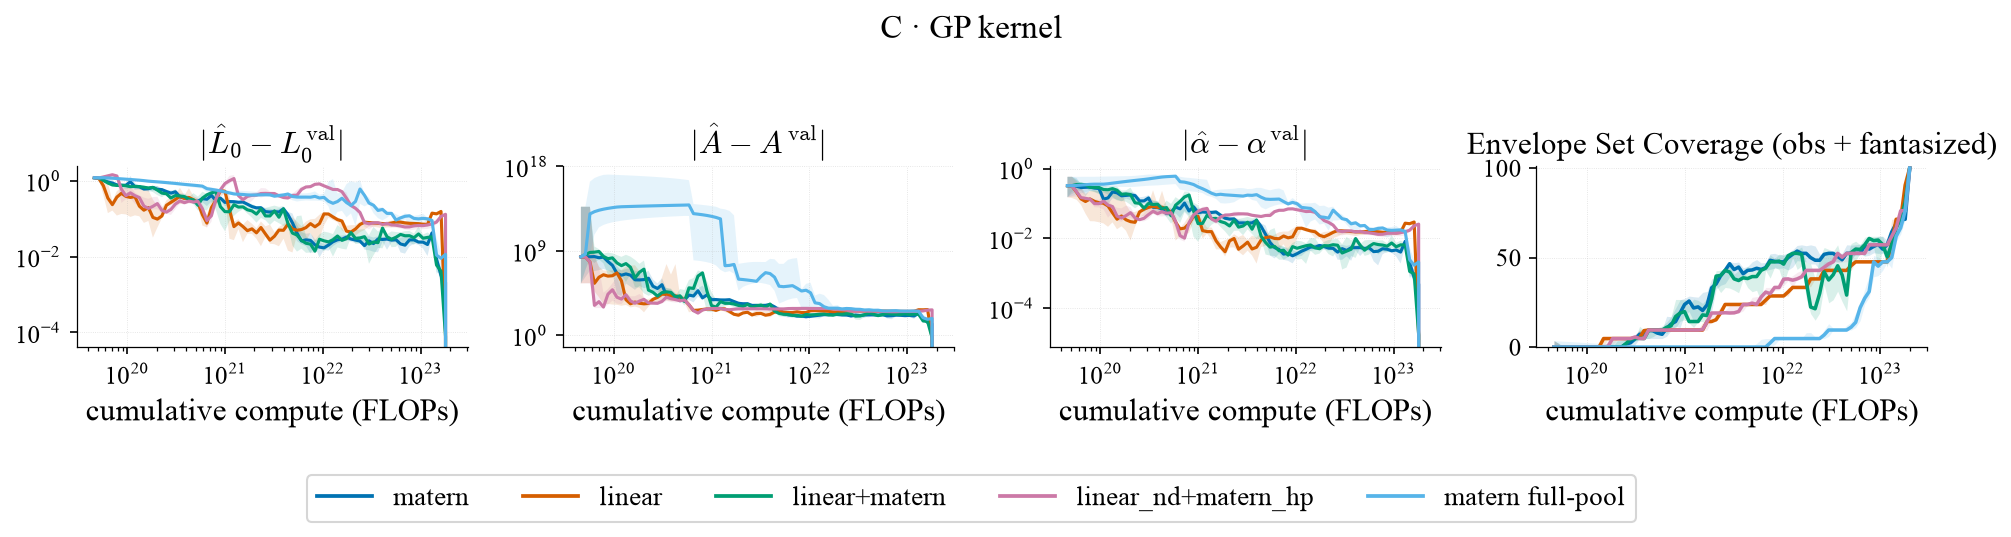

[gp_kernels] arms with runs: ['k_matern', 'k_linear', 'k_linmat', 'k_lnd_mathp', 'vanilla'] | 21 envelope pts


In [9]:
arms = MANIFEST["ablations"]["gp_kernels"]["arms"]
recovery_strip("gp_kernels", arms, DATA / "oellm_english" / "preprocessed" / "oellm_english.csv",
               title="C · GP kernel")

<a id="D"></a>
## D · acquisition

Acquisition function (`ablation_acquisition`): EI / PI / LCB window arms + full-pool `vanilla`.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


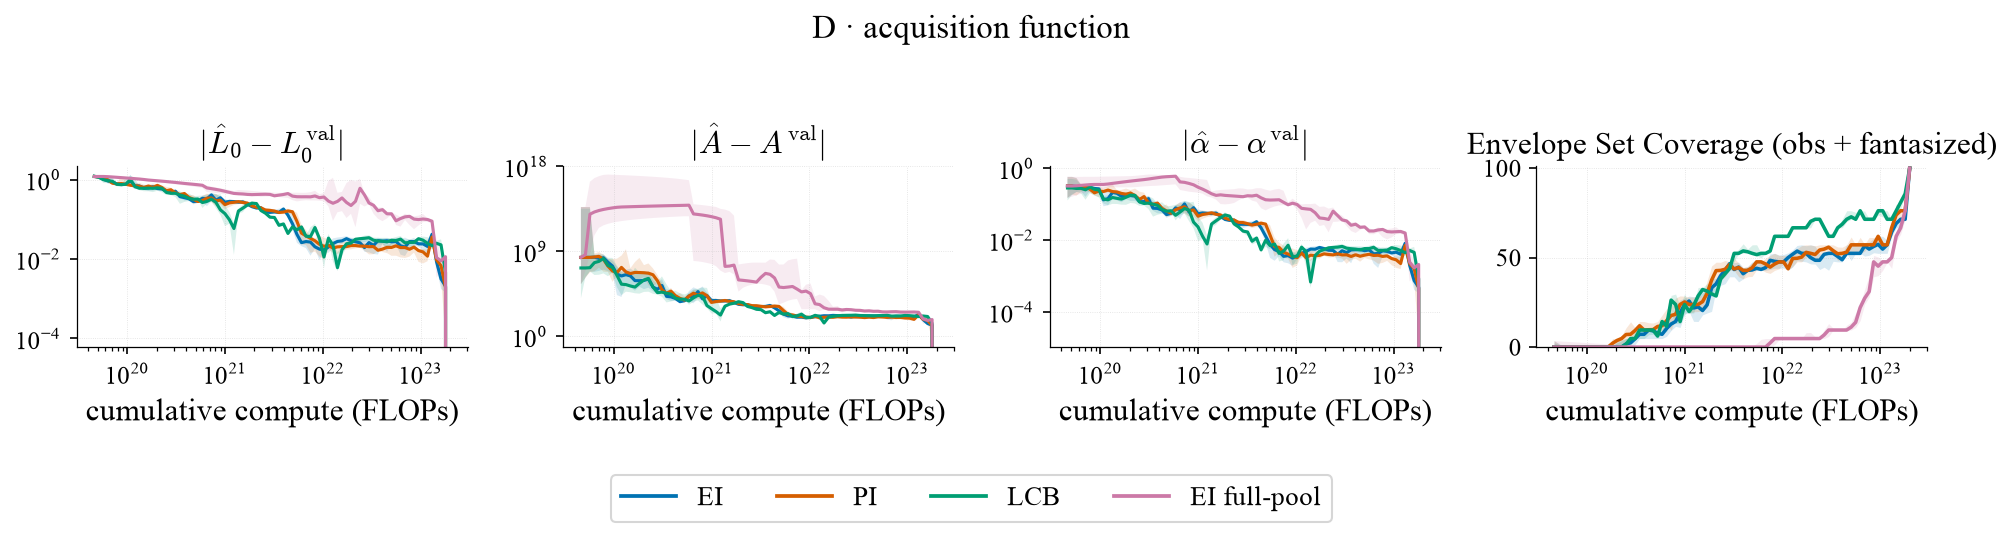

[acquisition] arms with runs: ['af_ei', 'af_pi', 'af_lcb', 'vanilla'] | 21 envelope pts


In [10]:
arms = MANIFEST["ablations"]["acquisition"]["arms"]
recovery_strip("acquisition", arms, DATA / "oellm_english" / "preprocessed" / "oellm_english.csv",
               title="D · acquisition function")

<a id="Ew"></a>
## E-window · window_growth

Growing vs sliding compute window (`ablation_window_growth`) + no-window `vanilla`.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


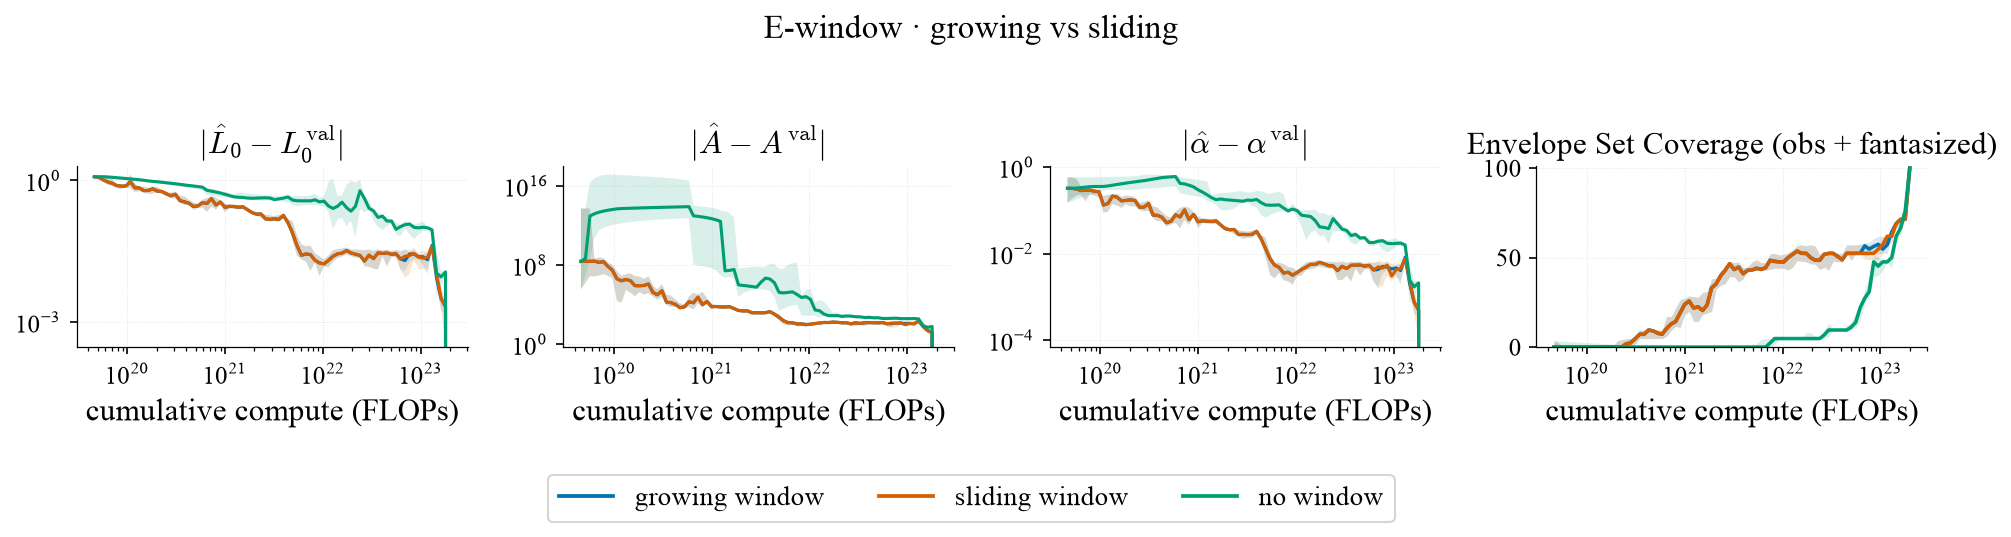

[window_growth] arms with runs: ['growing', 'sliding', 'vanilla'] | 21 envelope pts


In [11]:
arms = MANIFEST["ablations"]["window_growth"]["arms"]
recovery_strip("window_growth", arms, DATA / "oellm_english" / "preprocessed" / "oellm_english.csv",
               title="E-window · growing vs sliding")

<a id="Ec"></a>
## E-cost · cost_aware

Windowing vs cost-weighting (`ablation_cost_aware`): EI full / EI window / EI÷log(cost) / EI÷cost.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


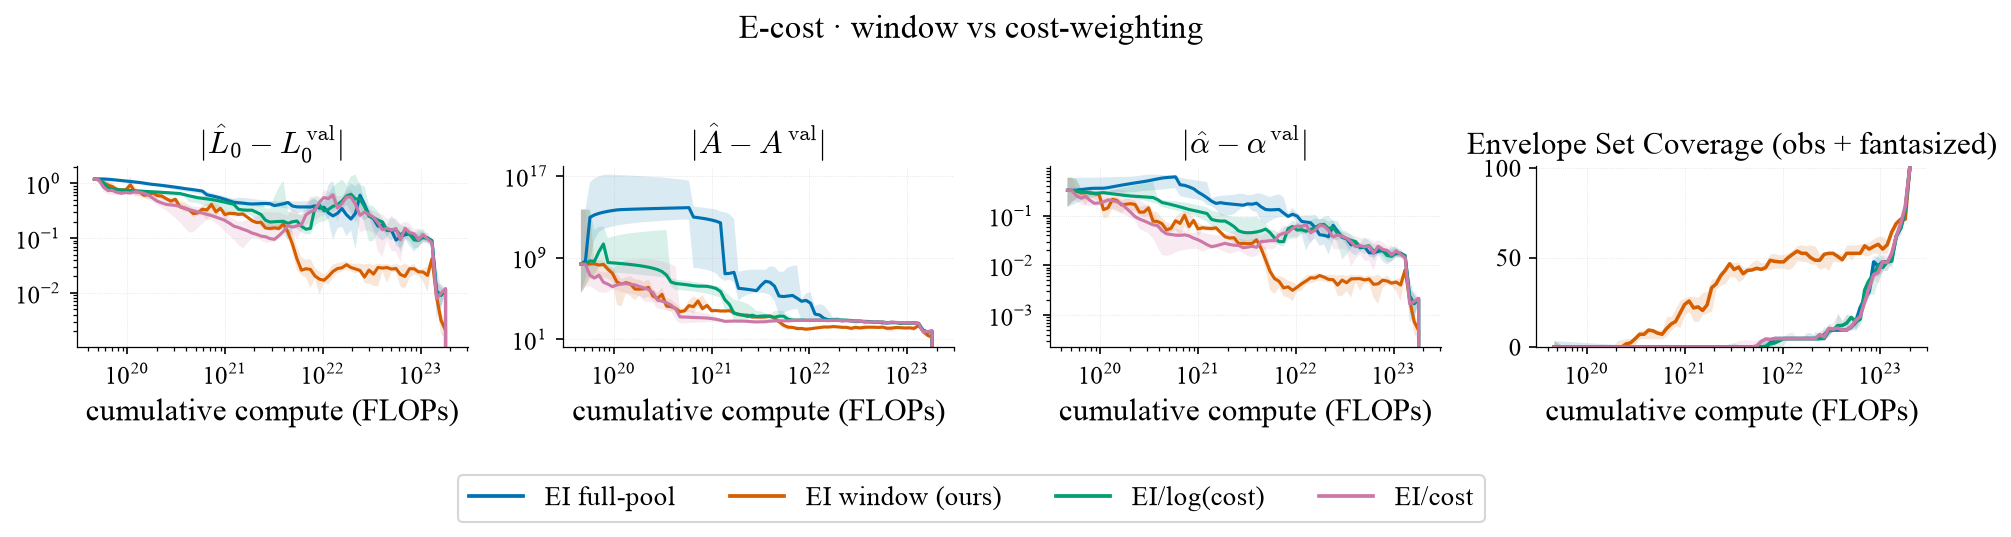

[cost_aware] arms with runs: ['ei_full', 'ei_window', 'ei_logcost', 'ei_hardcost'] | 21 envelope pts


In [12]:
arms = MANIFEST["ablations"]["cost_aware"]["arms"]
recovery_strip("cost_aware", arms, DATA / "oellm_english" / "preprocessed" / "oellm_english.csv",
               title="E-cost · window vs cost-weighting")